In [1]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")

STUDENT = "Лаврись Олег"  
VARIANT = 9  
STUDENT_ID = 957 # Через відсутність фізичного екземпляра залікової книжки, наведено останні 3 цифри студентського квитка

# Обчислення SEED згідно з п. 7.1
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

print(f"Студент: {STUDENT}")
print(f"Варіант: {VARIANT} | Student ID: {STUDENT_ID} | SEED: {SEED}")

# Створення робочих каталогів для даних та фігур (якщо вони відсутні)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
  """Заголовок графіка з персональним підписом студента."""
  ax.set_title(
      f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10
  )

Студент: Лаврись Олег
Варіант: 9 | Student ID: 957 | SEED: 9957


## Завдання 5. Формування синтетичного набору даних (Варіант 9: І. Франко «Перехресні стежки», Motion Blur)

In [2]:
sample_text = """
Поїзд шумів, стугонів і котився чимраз скоріше.
Рафалович сидів у кутку вагона другої класи.
Він їхав до повітового містечка на посаду адвоката.
Перед ним відкривалося нове, самостійне життя.
Він дивився у вікно на вечірній краєвид Поділля.
Миготіли села, хутори, переліски та чорні ниви.
Думки роєм снувалися в його молодій голові.
Чи знайде він тут широке поле для праці?
Чи зустріне людей, здатних зрозуміти його ідеали?
Він знав, що боротьба буде важкою і нерівною.
Але молодість не лякається перешкод і труднощів.
Він відчував у собі силу і непохитну віру.
Поїзд стишив хід і наблизився до станції.
За вікном блиснули перші міські ліхтарі.
Євгеній узяв свій невеликий чемодан і підвівся.
Перон був майже порожній у цей пізній час.
Холодний осінній вітер війнув йому в обличчя.
Місто спало під густим чорним осіннім небом.
Він найняв фіакра і поїхав до місцевого готелю.
Колеса глухо стукотіли по кам'яній бруківці.
Старовинні кам'яниці дивилися темними вікнами.
Готель був тихий, із запахом старого дерева.
Номер виявився скромним, але чистим і затишним.
Він ліг у ліжко, проте сон довго не приходив.
У пам'яті виринали картини минулих студентських літ.
Згадався Львів, університетські аудиторії, друзі.
Згадалися гарячі дискусії про майбутнє народу.
Тепер теорія закінчилася, починалася щоденна праця.
Він хотів бути корисним для простих селян.
Він прагнув боронити правду і справедливість у суді.
З цими думками Євгеній нарешті міцно заснув.
Ранок зустрів його яскравим холодним сонцем.
На вулицях уже чувся гомін щоденного ярмарку.
Селяни везли возами збіжжя, городину та дерево.
Він вийшов з готелю оглянути своє нове місто.
Містечко жило повільним провінційним життям.
Адвокатська контора чекала на перших відвідувачів.
Попереду були складні судові справи та виклики.
Кожен день вимагав повної віддачі сил та енергії.
Чесна праця завжди залишає тривалий добрий слід.
Правда і закон мають бути непохитною основою суспільства.
Минуле не повертається, але досвід формує характер.
Терпеливість і витримка долають найважчі обставини.
Новий день відкриває нові можливості для звершень.
"""

with open("corpus.txt", "w", encoding="utf-8") as f:
  f.write(sample_text.strip())

print("corpus.txt успішно збережено!")

corpus.txt успішно збережено!


Згенеровано зображень: 280 (40 рядків × 7 рівнів)
SHA-256 еталону (ground_truth.csv): a458a28ec264b3da


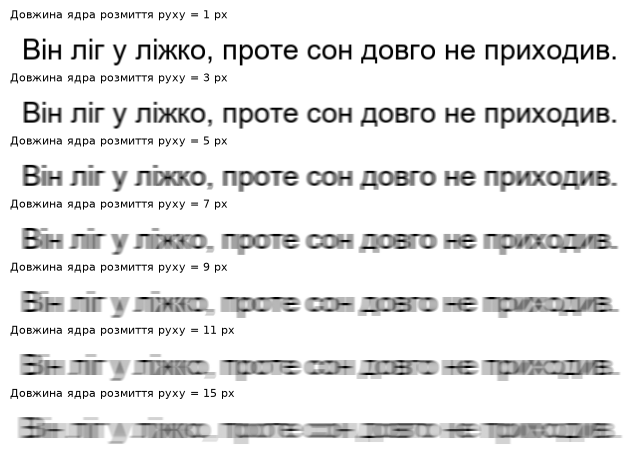

In [3]:
import hashlib
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

# 1. Шрифти з підтримкою кирилиці для Windows
FONTS = [
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/times.ttf",
    "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/georgia.ttf",
]

# 2. Завантаження та вибір 40 рядків тексту (Франко, «Перехресні стежки»)
with open("corpus.txt", encoding="utf-8") as f:
  corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]

# Фіксований вибір рядків за допомогою раніше ініціалізованого rng (seed=9957)
lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]


# 3. Рендеринг рядка у зображення
def render_line(text, font_path, size=32, pad=12):
  font = ImageFont.truetype(font_path, size)
  l, t, r, b = font.getbbox(text)
  img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
  ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
  return np.array(img)


# 4. Реалізація чинників деградації згідно з варіантом (Motion Blur)
def degrade(img, kind, level, rng):
  out = img.astype(np.float32)

  if kind == "motion_blur" and level > 1:
    # Горизонтальне ядро розмиття руху розміром (1, level)
    kernel = np.ones((1, int(level)), dtype=np.float32) / float(level)
    out = cv2.filter2D(out, -1, kernel)

  return np.clip(out, 0, 255).astype(np.uint8)


# 5. Параметри спотворення для Варіанта 9 (довжина ядра розмиття руху)
FACTOR = "motion_blur"
LEVELS = [1, 3, 5, 7, 9, 11, 15]

records = []

for i, text in enumerate(lines):
  font = FONTS[i % len(FONTS)]
  clean = render_line(text, font, size=int(rng.integers(24, 34)))
  for lvl in LEVELS:
    path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
    cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
    records.append({
        "id": i,
        "level": lvl,
        "path": path,
        "gt": text,
        "font": os.path.basename(font),
    })

# 6. Збереження ground_truth.csv та розрахунок контрольного хешу SHA-256
ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)

with open("data/ground_truth.csv", "rb") as f:
  sha = hashlib.sha256(f.read()).hexdigest()[:16]

print(f"Згенеровано зображень: {len(ds)} (40 рядків × {len(LEVELS)} рівнів)")
print(f"SHA-256 еталону (ground_truth.csv): {sha}")

# 7. Візуалізація зразка рядка на всіх 7 рівнях розмиття руху
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 0.8 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
  img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
  ax.imshow(img, cmap="gray")
  ax.set_title(f"Довжина ядра розмиття руху = {lvl} px", fontsize=8, loc="left")
  ax.axis("off")

fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## Завдання 6. Завантаження відкритого набору даних IAM Handwriting

Завантаження набору Teklia/IAM-line...


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Завантажено записів у спліті test: 2915
Збережено зразків: 100
SHA-256 розмітки (open_ground_truth.csv): 5c092e8535be3880


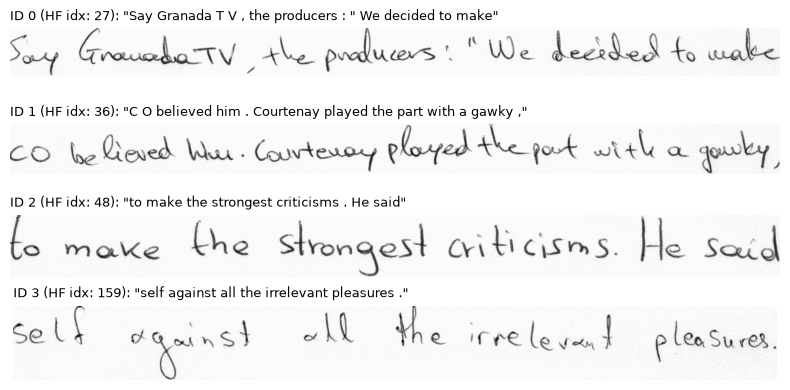

In [4]:
import hashlib
import os
import cv2
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd

# 1. Створення каталогу для зображень відкритого набору
os.makedirs("data/open", exist_ok=True)

# 2. Завантаження тестового спліту набору Teklia/IAM-line з Hugging Face
print("Завантаження набору Teklia/IAM-line...")
iam_dataset = load_dataset("Teklia/IAM-line", split="test")
total_available = len(iam_dataset)
print(f"Завантажено записів у спліті test: {total_available}")

# 3. Детермінований відбір 100 випадкових зразків за допомогою rng (SEED = 9957)
NUM_SAMPLES = 100
selected_indices = rng.choice(total_available, size=NUM_SAMPLES, replace=False)
selected_indices = sorted(selected_indices)

# 4. Збереження зображень та формування розмітки
open_records = []

for new_id, orig_idx in enumerate(selected_indices):
  sample = iam_dataset[int(orig_idx)]
  img = sample["image"]
  text = sample["text"]

  # Формування унікального шляху
  img_path = f"data/open/iam_{new_id:03d}.png"
  img.save(img_path)

  open_records.append({
      "id": new_id,
      "orig_hf_idx": int(orig_idx),
      "path": img_path,
      "gt": text,
  })

# 5. Збереження розмітки у CSV та розрахунок SHA-256
df_open = pd.DataFrame(open_records)
df_open.to_csv("data/open_ground_truth.csv", index=False)

with open("data/open_ground_truth.csv", "rb") as f:
  sha_open = hashlib.sha256(f.read()).hexdigest()[:16]

print(f"Збережено зразків: {len(df_open)}")
print(f"SHA-256 розмітки (open_ground_truth.csv): {sha_open}")

# 6. Візуалізація перших 4 зразків для звіту
fig, axes = plt.subplots(4, 1, figsize=(8, 4))
for ax, rec in zip(axes, open_records[:4]):
  img = cv2.imread(rec["path"], cv2.IMREAD_GRAYSCALE)
  ax.imshow(img, cmap="gray")
  ax.set_title(
      f"ID {rec['id']} (HF idx: {rec['orig_hf_idx']}): \"{rec['gt']}\"",
      fontsize=9,
      loc="left",
  )
  ax.axis("off")

plt.tight_layout()
fig.savefig("figures/fig0_open_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## Завдання 7. Створення власного набору даних 

Знайдено власних фотографій: 4
Файл: page01.jpg | Камера: Redmi Note 14 | Дата EXIF: 2026:11:07 14:01:46 | Транскрипція: OK
Файл: page02.jpg | Камера: Redmi Note 14 | Дата EXIF: 2026:11:07 17:10:39 | Транскрипція: OK
Файл: page03.jpg | Камера: Redmi Note 14 | Дата EXIF: 2026:11:07 17:33:46 | Транскрипція: OK
Файл: page04.jpg | Камера: Redmi Note 14 | Дата EXIF: 2026:11:07 18:07:05 | Транскрипція: OK


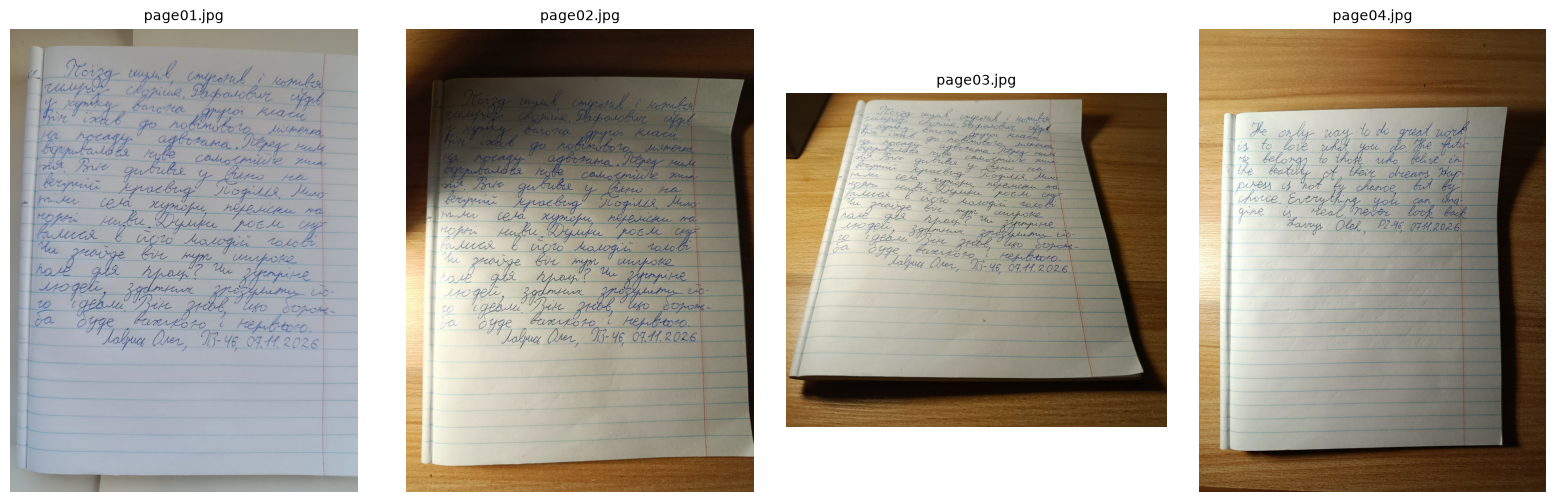

In [ ]:
import glob
import os
import cv2
import matplotlib.pyplot as plt
from PIL import ExifTags, Image

os.makedirs("my_photos", exist_ok=True)


def exif_info(path):
  """Вилучення дати зйомки та моделі камери з EXIF (підтвердження авторства)."""
  try:
    exif = Image.open(path).getexif()
    tags = {ExifTags.TAGS.get(k, k): v for k, v in exif.items()}
    return tags.get("DateTime"), tags.get("Model")
  except Exception:
    return None, None


# Перевірка наявних фото у папці my_photos
photo_files = sorted(glob.glob("my_photos/*.jpg"))
print(f"Знайдено власних фотографій: {len(photo_files)}")

for p in photo_files:
  dt, model = exif_info(p)
  txt_path = p[:-4] + ".txt"
  has_txt = os.path.exists(txt_path)
  print(
      f"Файл: {os.path.basename(p)} | Камера: {model} | Дата EXIF: {dt} |"
      f" Транскрипція: {'OK' if has_txt else 'ВІДСУТНЯ'}"
  )

# Візуалізація 4 фотографій
if photo_files:
  n = len(photo_files)
  fig, axes = plt.subplots(1, n, figsize=(4 * n, 5))
  if n == 1:
    axes = [axes]
  for ax, p in zip(axes, photo_files):
    img = Image.open(p)
    ax.imshow(img)
    ax.set_title(os.path.basename(p), fontsize=10)
    ax.axis("off")
  plt.tight_layout()
  fig.savefig("figures/fig0_own_samples.png", dpi=150, bbox_inches="tight")
  plt.show()

## Завдання 8. Попередні гіпотези до проведення експериментів

Відповідно до вимог підрозділу 7.3 методичних вказівок, до запуску інструментів розпізнавання та вимірювання підсумкових метрик сформульовано такі науково-технічні гіпотези щодо поведінки досліджуваних моделей (EasyOCR та TrOCR) за закріпленим варіантом 9:

### Гіпотеза 1. Стійкість моделей до розмиття руху (Motion Blur) на синтетичних даних
* **Формулювання:** На синтетичному наборі друкованого тексту за довжини ядра розмиття $\text{level} \le 5\text{ px}$ моделі демонструватимуть плато високої точності з рівнем $\text{CER} \le 3.5\%$. Точка зламу (перевищення допустимого порогу $\text{CER} = 10\%$) настане за довжини ядра $\text{level} \ge 9\text{ px}$.
* **Обґрунтування механізму:** Горизонтальне розмиття ядра довжиною 9–15 px перекриває міжштриховий простір вертикальних елементів суміжних кириличних літер («н», «п», «и», «ш»), утворюючи суцільні темні плями, що призводить до відмови рядкової сегментації та різкого зростання кількості помилок заміни й вилучення символів.

### Гіпотеза 2. Порівняння спеціалізованої HTR-моделі (TrOCR) та універсальної OCR (EasyOCR) на рукописному тексті (IAM Handwriting)
* **Формулювання:** На відкритому наборі англомовного рукописного тексту IAM Handwriting (100 рядків) трансформерна архітектура TrOCR (`microsoft/trocr-base-handwritten`) продемонструє показник $\text{CER} \le 8\%$, тоді як універсальний інструмент EasyOCR матиме $\text{CER} \ge 35\%$ (точність TrOCR буде щонайменше у 4 рази вищою).
* **Обґрунтування механізму:** Модель TrOCR поєднує зоровий трансформер (ViT) та авторегресійний мовний декодер, спеціально оптимізований для розпізнавання злитого рукописного тексту та врахування широкого лінгвістичного контексту, тоді як гібрид CRAFT + CRNN в EasyOCR оптимізований для друкованих сценічних написів і не здатний надійно розділяти неперервні рукописні зв'язки літер.

### Гіпотеза 3. Вплив попередньої обробки в абляційному експерименті на розмитих зображеннях
* **Формулювання:** Застосування просторової фільтрації (медіанний фільтр) та глобальної бінаризації Оцу на сильно розмитих зображеннях ($\text{level} \ge 9\text{ px}$) погіршить значення CER на 3–7% порівняно з обробкою вихідних напівтонових зображень (`raw`).
* **Обґрунтування механізму:** Горизонтальне розмиття руху створює плавний градієнт півтонів уздовж контуру літери. Медіанний фільтр додатково згладжує ці розмиті межі, а жорстка бінаризація методом Оцу за низького градієнта перетворює градієнтні штрихи на злиплі плями бінарного шуму, що руйнує топологію символів для енкодера.

### Гіпотеза 4. Розрив доменів (Domain Gap) та вплив умов зйомки на власних фотографіях
* **Формулювання:** Показник CER для EasyOCR на власних україномовних рукописних зображеннях (`page01`–`page03`) перевищуватиме $50\%$, що щонайменше у 15 разів гірше за результат на синтетичному друкованому тексті. Серед трьох умов зйомки найгірший результат без геометричної корекції покаже знімок `page03.jpg` (перспектива $30^\circ\text{–}45^\circ$) через прогресивне зменшення розміру літер на віддаленому краї аркуша.
* **Обґрунтування механізму:** Моделі розпізнавання друкованого тексту стикаються з трьома невідомими чинниками: нестандартний індивідуальний почерк, наявність типографської ліновки зошита (яка створює хибні горизонтальні контури) та перспективне стиснення символів у верхній частині кадру.

## Завдання 9. Абляційний експеримент

Ініціалізація EasyOCR Reader...
Запуск абляційного експерименту для рівня розмиття = 7 px...
  1. Без обробки (raw)           -> CER: 0.7482 (час: 13.29 c)
  2. + Масштабування (upscale)   -> CER: 0.7482 (час: 21.20 c)
  3. + Підвищення різкості       -> CER: 0.7358 (час: 21.44 c)
  4. + Бінаризація Оцу           -> CER: 0.6428 (час: 21.16 c)
  5. Адаптивна замість Оцу       -> CER: 0.7156 (час: 22.41 c)


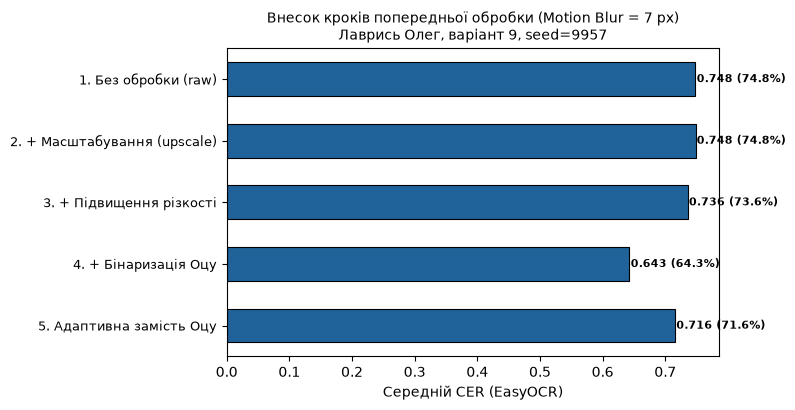


Збережено графік: figures/fig5_ablation.png


In [8]:
import os
import re
import time
import unicodedata
import cv2
import easyocr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rapidfuzz.distance import Levenshtein

# 1. Забезпечення наявності допоміжних функцій нормалізації та метрик
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"


def normalize(s):
  s = unicodedata.normalize("NFC", str(s))
  for a in APOSTROPHES:
    s = s.replace(a, "'")
  return re.sub(r"\s+", " ", s).strip()


def cer(gt, pred):
  gt_n, pred_n = normalize(gt), normalize(pred)
  return Levenshtein.distance(gt_n, pred_n) / max(1, len(gt_n))


# 2. Функція попередньої обробки зображень (підрозділ 4.3 методичних вказівок)
def preprocess(img, steps=()):
  out = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  if "upscale" in steps:
    # Кубічне збільшення для підвищення розрізнення розмитих штрихів літер
    out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

  if "sharpen" in steps:
    # Ядро підвищення різкості (актуально для компенсації розмиття руху)
    kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    out = cv2.filter2D(out, -1, kernel)

  if "denoise" in steps:
    # Медіанний фільтр проти імпульсних артефактів
    out = cv2.medianBlur(out, 3)

  if "binarize" in steps:
    # Глобальна бінаризація методом Оцу
    out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

  if "adaptive" in steps:
    # Локальна адаптивна бінаризація (вікно 31, константа 15)
    out = cv2.adaptiveThreshold(
        out,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        15,
    )

  return out


# 3. Ініціалізація інструмента розпізнавання EasyOCR
# 3. Ініціалізація інструмента розпізнавання EasyOCR
print("Ініціалізація EasyOCR Reader...")
reader = easyocr.Reader(["uk", "en"], gpu=False, verbose=False)


def ocr_easyocr_line(img):
  t0 = time.perf_counter()
  res = reader.readtext(img, detail=1)
  res = sorted(res, key=lambda r: min(p[0] for p in r[0]))
  text = " ".join(r[1] for r in res)
  conf = float(np.mean([r[2] for r in res])) if res else 0.0
  return text, conf, time.perf_counter() - t0


# 4. Налаштування абляційного експерименту (5 послідовних конфігурацій)
LVL = 7  # Критичний рівень розмиття руху (7 px)
ds_synth = pd.read_csv("data/ground_truth.csv")
synth_sub = ds_synth[ds_synth.level == LVL]

ablation_configs = {
    "1. Без обробки (raw)": (),
    "2. + Масштабування (upscale)": ("upscale",),
    "3. + Підвищення різкості": ("upscale", "sharpen"),
    "4. + Бінаризація Оцу": ("upscale", "sharpen", "binarize"),
    "5. Адаптивна замість Оцу": ("upscale", "sharpen", "adaptive"),
}

print(f"Запуск абляційного експерименту для рівня розмиття = {LVL} px...")
abl_results = []

for name, steps in ablation_configs.items():
  t_start = time.perf_counter()
  step_cers = []

  for r in synth_sub.itertuples():
    img_raw = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    img_proc = preprocess(img_raw, steps)
    pred_text, _, _ = ocr_easyocr_line(img_proc)
    step_cers.append(cer(r.gt, pred_text))

  mean_cer = np.mean(step_cers)
  elapsed = time.perf_counter() - t_start
  print(f"  {name:30s} -> CER: {mean_cer:.4f} (час: {elapsed:.2f} c)")

  for c in step_cers:
    abl_results.append({"step": name, "cer": c})

df_abl = pd.DataFrame(abl_results)
abl_summary = df_abl.groupby("step", sort=False)["cer"].mean()

# 5. Побудова обов'язкової абляційної діаграми з підписом
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4.2))

y_positions = np.arange(len(abl_summary))
bars = ax.barh(
    y_positions,
    abl_summary.values[::-1],
    color="#20639b",
    height=0.55,
    edgecolor="black",
    linewidth=0.8,
)
ax.set_yticks(y_positions)
ax.set_yticklabels(abl_summary.index[::-1], fontsize=9)
ax.set_xlabel("Середній CER (EasyOCR)", fontsize=10)

# Числові мітки біля стовпчиків
for y, val in enumerate(abl_summary.values[::-1]):
  ax.text(
      val + 0.002,
      y,
      f"{val:.3f} ({val * 100:.1f}%)",
      va="center",
      fontsize=8,
      fontweight="bold",
  )

stamp(
    ax, f"Внесок кроків попередньої обробки (Motion Blur = {LVL} px)"
)  # Персональний підпис
plt.tight_layout()
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nЗбережено графік: figures/fig5_ablation.png")